<a href="https://colab.research.google.com/github/kshitij-nandanwar/GenAI/blob/main/Practical_5_GenAI.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Transfer Learning for Text Classification
### News categorization: Sports vs Politics vs Technology

This notebook fine-tunes a **pre-trained transformer language model** (DistilBERT) on a **small, limited amount of labeled data** to classify news articles into three categories: `sport`, `politics`, `tech`. This is a classic transfer-learning workflow: instead of training a model from scratch (which would need tens of thousands of labeled examples), we start from a model already pre-trained on a huge text corpus and fine-tune only on our small labeled set.

**Dataset (real, not mock):** BBC News dataset by D. Greene and P. Cunningham (2006) — 2,225 real BBC news articles across 5 categories (business, entertainment, politics, sport, tech). We filter down to the 3 categories you asked for: **sport, politics, tech**.

This version loads the dataset from a **Kaggle CSV** you download and upload yourself (e.g. "BBC News Classification" or the `learn-ai-bbc` competition file), since the original UCD zip host can be unreliable:
- https://www.kaggle.com/datasets/hgultekin/bbcnewsarchive
- https://www.kaggle.com/c/learn-ai-bbc/data
- https://www.kaggle.com/datasets/yufengdev/bbc-text-categorization

Download the CSV from any one of these (Kaggle account required, it's free), then upload it in Step 3 below.

**Before you run:** In Colab, go to `Runtime > Change runtime type > Hardware accelerator > GPU (T4)` for much faster training. Then run the cells top to bottom with `Runtime > Run all` — you'll be prompted to upload your CSV partway through.


## Step 1 — Install libraries

In [1]:
!pip install -q transformers datasets torch scikit-learn pandas matplotlib seaborn accelerate


## Step 2 — Imports and reproducibility

In [2]:
import os, glob, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score
from datasets import Dataset
from transformers import (AutoTokenizer, AutoModelForSequenceClassification,
                           TrainingArguments, Trainer, DataCollatorWithPadding)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Using device:", device)


Using device: cuda


## Step 3 — Upload your Kaggle CSV dataset

The UCD server can be flaky, so this version loads the **BBC News dataset from Kaggle** instead (e.g. "BBC News Classification" / `bbc-text.csv`, or the `learn-ai-bbc` competition file — both are the same real 2,225-article BBC News corpus, just packaged as CSV instead of folders of `.txt` files).

Run the cell below, then click **"Choose Files"** and select the CSV you downloaded from Kaggle.

In [3]:
from google.colab import files

uploaded = files.upload()  # select your Kaggle CSV (e.g. bbc-text.csv or BBC News.csv)
csv_filename = list(uploaded.keys())[0]
print("Loaded file:", csv_filename)


Saving bbc-news-data.csv to bbc-news-data.csv
Loaded file: bbc-news-data.csv


## Step 4 — Load into a DataFrame and normalize column names

Different Kaggle uploads of this dataset use slightly different column names (`text`/`category` in some, `Text`/`Category`/`ArticleId` in others). This cell also uses a more tolerant CSV parser as a fallback: article text can contain raw commas, quotes, or line breaks that trip up pandas' fast default parser (`ParserError: Expected N fields, saw M`), so if the default read fails we retry with the slower but far more forgiving Python engine.

In [5]:
import csv

def robust_read_csv(path):
    # Try the most common delimiters explicitly and keep whichever produces more than one column
    for sep in [",", "\t", ";", "|"]:
        try:
            df_try = pd.read_csv(path, sep=sep, engine="python", on_bad_lines="skip")
            if df_try.shape[1] > 1:
                sep_name = {",": "comma", "\t": "tab", ";": "semicolon", "|": "pipe"}[sep]
                print(f"Parsed successfully using {sep_name}-separated values -> {df_try.shape[1]} columns")
                return df_try
        except Exception as e:
            print(f"Separator {repr(sep)} failed: {e}")
    # Last resort: let pandas sniff the delimiter itself
    print("Falling back to delimiter auto-detection...")
    return pd.read_csv(path, engine="python", sep=None, on_bad_lines="skip")

df_full = robust_read_csv(csv_filename)
print("Raw columns:", df_full.columns.tolist())
print("Rows loaded:", len(df_full))

cols_lower = {c.lower(): c for c in df_full.columns}
text_col = cols_lower.get("text") or cols_lower.get("content") or cols_lower.get("article")
cat_col = cols_lower.get("category") or cols_lower.get("label")

assert text_col is not None and cat_col is not None, (
    f"Could not auto-detect text/category columns. Found columns: {df_full.columns.tolist()}. "
    "Edit text_col / cat_col above to match your file manually."
)

df_full = df_full.rename(columns={text_col: "text", cat_col: "category"})[["text", "category"]]
df_full["category"] = df_full["category"].astype(str).str.strip().str.lower()
df_full = df_full.dropna(subset=["text", "category"]).reset_index(drop=True)

print("Total articles:", len(df_full))
print(df_full["category"].value_counts())
df_full.head()

Parsed successfully using tab-separated values -> 4 columns
Raw columns: ['category', 'filename', 'title', 'content']
Rows loaded: 2225
Total articles: 2225
category
sport            511
business         510
politics         417
tech             401
entertainment    386
Name: count, dtype: int64


,text,category
0,Quarterly profits at US media giant TimeWarne...,business
1,The dollar has hit its highest level against ...,business
2,The owners of embattled Russian oil giant Yuk...,business
3,British Airways has blamed high fuel prices f...,business
4,Shares in UK drinks and food firm Allied Dome...,business


## Step 5 — Filter to the 3 target categories: sport, politics, tech

In [6]:
target_categories = ["sport", "politics", "tech"]
df = df_full[df_full["category"].isin(target_categories)].reset_index(drop=True)

label2id = {c: i for i, c in enumerate(target_categories)}
id2label = {i: c for c, i in label2id.items()}
df["label"] = df["category"].map(label2id)

print(df["category"].value_counts())
df.head()


category
sport       511
politics    417
tech        401
Name: count, dtype: int64


,text,category,label
0,Maternity pay for new mothers is to rise by £...,politics,1
1,The information commissioner says he is urgen...,politics,1
2,Plans to extend paid maternity leave beyond s...,politics,1
3,The Labour Party will hold its 2006 autumn co...,politics,1
4,Chancellor Gordon Brown's closest ally has de...,politics,1


## Step 6 — Simulate a *limited labeled data* scenario

This is the core premise of the task: a news agency has only a small number of labeled articles per category. We take just **40 labeled examples per class for training** (120 total) and hold out the rest for validation/testing, then rely on transfer learning from the pre-trained model to still get strong performance.

In [7]:
N_PER_CLASS_TRAIN = 40  # simulate limited labeled data per category

train_frames, remainder_frames = [], []
for cat in target_categories:
    cat_df = df[df["category"] == cat].sample(frac=1, random_state=SEED)
    train_frames.append(cat_df.iloc[:N_PER_CLASS_TRAIN])
    remainder_frames.append(cat_df.iloc[N_PER_CLASS_TRAIN:])

train_df = pd.concat(train_frames).sample(frac=1, random_state=SEED).reset_index(drop=True)
remainder_df = pd.concat(remainder_frames).sample(frac=1, random_state=SEED).reset_index(drop=True)

val_df, test_df = train_test_split(
    remainder_df, test_size=0.5, stratify=remainder_df["label"], random_state=SEED
)

print("Train size:", len(train_df))
print("Val size:  ", len(val_df))
print("Test size: ", len(test_df))
train_df["category"].value_counts()


Train size: 120
Val size:   604
Test size:  605


,count
category,
politics,40
sport,40
tech,40


## Step 7 — Tokenize with the pre-trained model's tokenizer

In [8]:
MODEL_NAME = "distilbert-base-uncased"  # pre-trained language model we transfer from
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

def to_hf_dataset(pdf):
    return Dataset.from_pandas(pdf[["text", "label"]].reset_index(drop=True))

train_ds = to_hf_dataset(train_df)
val_ds = to_hf_dataset(val_df)
test_ds = to_hf_dataset(test_df)

def tokenize_fn(batch):
    return tokenizer(batch["text"], truncation=True, max_length=256)

train_ds = train_ds.map(tokenize_fn, batched=True)
val_ds = val_ds.map(tokenize_fn, batched=True)
test_ds = test_ds.map(tokenize_fn, batched=True)

data_collator = DataCollatorWithPadding(tokenizer=tokenizer)


config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Map:   0%|          | 0/120 [00:00<?, ? examples/s]

Map:   0%|          | 0/604 [00:00<?, ? examples/s]

Map:   0%|          | 0/605 [00:00<?, ? examples/s]

## Step 8 — Load the pre-trained model with a new classification head

This is the transfer-learning step: DistilBERT's pre-trained weights (learned from a huge general text corpus) are reused, and a fresh 3-way classification head is attached on top and fine-tuned on our small labeled dataset.

In [9]:
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=len(target_categories),
    id2label=id2label,
    label2id=label2id,
)


model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.weight       | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


## Step 9 — Define evaluation metrics

In [10]:
def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=1)
    return {
        "accuracy": accuracy_score(labels, preds),
        "f1_macro": f1_score(labels, preds, average="macro"),
    }


## Step 10 — Set training arguments and fine-tune

In [12]:
training_args = TrainingArguments(
    output_dir="./results",
    eval_strategy="epoch",
    save_strategy="epoch",
    learning_rate=2e-5,
    per_device_train_batch_size=8,
    per_device_eval_batch_size=16,
    num_train_epochs=6,
    weight_decay=0.01,
    load_best_model_at_end=True,
    metric_for_best_model="f1_macro",
    logging_steps=10,
    report_to="none",
    seed=SEED,
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_ds,
    eval_dataset=val_ds,
    processing_class=tokenizer,   # renamed from `tokenizer=` in newer transformers versions
    data_collator=data_collator,
    compute_metrics=compute_metrics,
)

trainer.train()

Epoch,Training Loss,Validation Loss,Accuracy,F1 Macro
1,1.073889,0.864634,0.988411,0.987529
2,0.585931,0.472270,0.988411,0.987517
3,0.370091,0.239525,0.988411,0.987502
4,0.162841,0.150912,0.986755,0.985704
5,0.113487,0.115602,0.986755,0.985696
6,0.087490,0.106437,0.986755,0.985696


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=90, training_loss=0.402201376358668, metrics={'train_runtime': 94.1696, 'train_samples_per_second': 7.646, 'train_steps_per_second': 0.956, 'total_flos': 47689113968640.0, 'train_loss': 0.402201376358668, 'epoch': 6.0})

## Step 11 — Evaluate on the held-out test set

              precision    recall  f1-score   support

       sport       1.00      1.00      1.00       236
    politics       1.00      0.97      0.98       189
        tech       0.97      0.99      0.98       180

    accuracy                           0.99       605
   macro avg       0.99      0.99      0.99       605
weighted avg       0.99      0.99      0.99       605



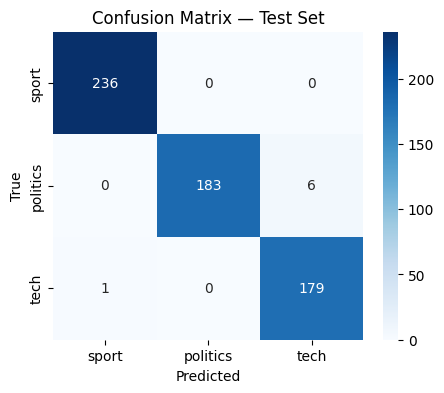

In [13]:
preds_output = trainer.predict(test_ds)
y_pred = np.argmax(preds_output.predictions, axis=1)
y_true = preds_output.label_ids

print(classification_report(y_true, y_pred, target_names=target_categories))

cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=target_categories, yticklabels=target_categories)
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion Matrix — Test Set")
plt.show()


## Step 12 — Try it on your own headlines

In [14]:
def predict_text(text):
    inputs = tokenizer(text, return_tensors="pt", truncation=True, max_length=256).to(model.device)
    with torch.no_grad():
        logits = model(**inputs).logits
    pred_id = torch.argmax(logits, dim=1).item()
    probs = torch.softmax(logits, dim=1)[0].tolist()
    return id2label[pred_id], {id2label[i]: round(p, 3) for i, p in enumerate(probs)}

samples = [
    "The prime minister announced a new policy on healthcare reform today in parliament.",
    "Manchester United won the match 3-1 with a stunning goal in the final minute.",
    "Apple unveiled its latest AI chip that promises faster on-device machine learning.",
]

for s in samples:
    label, probs = predict_text(s)
    print(f"Text: {s}\nPredicted: {label} | Probabilities: {probs}\n")


Text: The prime minister announced a new policy on healthcare reform today in parliament.
Predicted: politics | Probabilities: {'sport': 0.293, 'politics': 0.384, 'tech': 0.322}

Text: Manchester United won the match 3-1 with a stunning goal in the final minute.
Predicted: sport | Probabilities: {'sport': 0.407, 'politics': 0.294, 'tech': 0.299}

Text: Apple unveiled its latest AI chip that promises faster on-device machine learning.
Predicted: tech | Probabilities: {'sport': 0.332, 'politics': 0.259, 'tech': 0.409}



## Step 13 — Save the fine-tuned model

In [15]:
model.save_pretrained("./bbc-transfer-learning-model")
tokenizer.save_pretrained("./bbc-transfer-learning-model")
print("Model saved to ./bbc-transfer-learning-model")

# Optional: zip it and download to your computer
!zip -rq bbc-transfer-learning-model.zip bbc-transfer-learning-model
try:
    from google.colab import files
    files.download("bbc-transfer-learning-model.zip")
except ImportError:
    print("Not running in Colab — the zip is saved locally as bbc-transfer-learning-model.zip")


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Model saved to ./bbc-transfer-learning-model


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>